---

# Praktikum 2 IF3170 Inteligensi Artifisial

*Klasifikasi keterlambatan pengiriman pesanan.*

---

## K02_G08_kata mamah gaboleh sendiri

- 13524008 Agatha Tatianingseto
- 13524089 Aurelia Jennifer Gunawan

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Exploratory Data Analysis**](#3)
4. [**Data Cleaning and Preprocessing**](#4)
5. [**Modeling and Validation**](#5)
6. [**Error Analysis**](#6)
7. [**Submission**](#7)

---

# Introduction <a name="1"></a>

---

Notebook ini membangun model klasifikasi untuk memprediksi **keterlambatan pengiriman pesanan** (`is_delayed`: 1 = terlambat, 0 = tidak terlambat) berdasarkan data pesanan seperti hub pengiriman, jenis layanan, harga barang, diskon, berat tagihan, jumlah kontak dukungan, dan skor pelanggan. Data latih berisi 8.189 baris dan data test berisi 2.048 baris.

Alur pengerjaan:
1. **Exploratory Data Analysis**: memeriksa tipe data, missing value, duplikasi, distribusi, outlier, dan hubungan tiap fitur dengan `is_delayed`.
2. **Data Cleaning and Preprocessing**: membagi data menjadi data latih dan validasi, lalu menangani missing value dan nilai janggal, mengubah fitur kategorikal menjadi angka, serta memutuskan penanganan outlier dan class imbalance.
3. **Modeling and Validation**: melatih lima model (KNN, Decision Tree, SVM, Logistic Regression, dan Gaussian Naive Bayes), membandingkannya dengan holdout dan K-Fold Cross Validation, lalu melakukan hyperparameter tuning. Metrik yang dipakai adalah macro F1-score.
4. **Error Analysis**: menganalisis kesalahan prediksi model terbaik melalui confusion matrix, precision, recall, dan contoh data yang salah diprediksi.
5. **Submission**: melatih ulang model terbaik pada seluruh data latih untuk memprediksi data test dan menghasilkan `submission.csv`.

---

# Initialization <a name="2"></a>

---

Persiapan pustaka, pengaturan, dan dataset yang tidak perlu diubah.

## Environment Setup

Seluruh library yang dipakai notebook ini.

In [1]:
%pip install gdown imbalanced-learn matplotlib numpy pandas scikit-learn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Seluruh import untuk notebook ini dikumpulkan pada satu sel.

In [2]:
import random
from pathlib import Path

import gdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder, RobustScaler, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

## Settings

Path, seed, pengaturan validasi, dan tautan dataset berada pada `Settings`.

In [3]:
class Settings:
    SEED = 42
    DATA_DIR = Path('data')
    OUTPUT_DIR = Path('output')
    ID_COLUMN = 'id'
    TARGET = 'is_delayed'
    TEST_SIZE = 0.2
    N_FOLDS = 5
    URLS = {
        'train': 'https://drive.google.com/uc?id=14PfSAk0dBbLkcF_rn5WyLSdCLdYF2lD6',
        'test': 'https://drive.google.com/uc?id=1Pl3Q_4kcS1W-xr_rd5JaQ0ns-oC4NhHr',
        'sample_submission': 'https://drive.google.com/uc?id=1xO4cZ20aoaku7Cg8MC-KbWSkKku0hT0u',
    }

Settings.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
random.seed(Settings.SEED)
np.random.seed(Settings.SEED)

Settings.DATA_DIR

PosixPath('data')

#### Pertanyaan

> Apakah seed perlu ditetapkan pada praktikum ini? Bagaimana jika tidak ditetapkan?

> Seed perlu ditetapkan agar notebook reproducible dan menghasilkan hasil yang sama ketika dirun oleh orang yang berbeda.

## Load Dataset

Berkas yang belum ada pada `data` diunduh dengan gdown, lalu `train.csv` dan `test.csv` dibaca dengan kolom `id` sebagai teks.

In [4]:
Settings.DATA_DIR.mkdir(parents=True, exist_ok=True)

for name, url in Settings.URLS.items():
    path = Settings.DATA_DIR / f'{name}.csv'

    if not path.exists():
        gdown.download(url, str(path), quiet=True)

sorted(path.name for path in Settings.DATA_DIR.glob('*.csv'))

['sample_submission.csv', 'test.csv', 'train.csv']

In [5]:
train = pd.read_csv(Settings.DATA_DIR / 'train.csv', dtype={Settings.ID_COLUMN: str})
test = pd.read_csv(Settings.DATA_DIR / 'test.csv', dtype={Settings.ID_COLUMN: str})

pd.Series({'train': len(train), 'test': len(test)})

train    8189
test     2048
dtype: int64

---

# Exploratory Data Analysis <a name="3"></a>

---

Pemeriksaan data sebelum pemodelan.

## Data Overview

Gambaran awal `train` dan `test`.

Sekilas data.

In [6]:
display(train.shape)

train.describe()

(8189, 12)

,item_price_idr,discount_idr,billable_weight_kg,previous_orders,support_contacts,customer_score,is_delayed
count,7.884000e+03,8189.000000,8010.000000,8189.000000,8189.000000,7665.000000,8189.000000
mean,2.201519e+05,20066.833557,4.632452,3.569056,4.055807,3.000783,0.625595
std,1.493064e+05,24320.722828,2.200919,1.512051,1.143229,1.409037,0.483998
min,9.590000e+04,1200.000000,0.000000,2.000000,2.000000,1.000000,0.000000
25%,1.698000e+05,5900.000000,2.330000,3.000000,3.000000,2.000000,0.000000
50%,2.158000e+05,10600.000000,5.360000,3.000000,4.000000,3.000000,1.000000
75%,2.512000e+05,15200.000000,6.530000,4.000000,5.000000,4.000000,1.000000
max,2.749900e+06,97800.000000,10.200000,10.000000,7.000000,5.000000,1.000000


In [7]:
display(test.shape)

test.describe()

(2048, 11)

,item_price_idr,discount_idr,billable_weight_kg,previous_orders,support_contacts,customer_score
count,1.960000e+03,2048.000000,2001.000000,2048.000000,2048.000000,1931.000000
mean,2.221212e+05,19756.298828,4.646742,3.591797,4.022461,2.954428
std,1.620677e+05,24027.893524,2.199980,1.579785,1.143142,1.421520
min,9.670000e+04,1200.000000,0.000000,2.000000,2.000000,1.000000
25%,1.710000e+05,5800.000000,2.360000,3.000000,3.000000,2.000000
50%,2.153500e+05,10400.000000,5.350000,3.000000,4.000000,3.000000
75%,2.520000e+05,15200.000000,6.560000,4.000000,5.000000,4.000000
max,2.689900e+06,97800.000000,9.860000,10.000000,7.000000,5.000000


Tipe data. `types` menampilkan dtype, jenis kolom, dan jumlah nilai unik dari satu DataFrame.

In [8]:
def types(df):
    kinds = ['numeric' if pd.api.types.is_numeric_dtype(df[column]) else 'categorical' for column in df]

    return pd.DataFrame({'dtype': df.dtypes.astype(str), 'kind': kinds, 'unique': df.nunique()})

In [9]:
display(types(train))

,dtype,kind,unique
id,object,categorical,8189
fulfillment_hub,object,categorical,5
delivery_service,object,categorical,3
item_tier,object,categorical,3
item_price_idr,float64,numeric,1726
discount_idr,int64,numeric,450
billable_weight_kg,float64,numeric,657
previous_orders,int64,numeric,8
support_contacts,int64,numeric,6
customer_score,float64,numeric,5


In [10]:
display(types(test))

,dtype,kind,unique
id,object,categorical,2048
fulfillment_hub,object,categorical,5
delivery_service,object,categorical,3
item_tier,object,categorical,3
item_price_idr,float64,numeric,1107
discount_idr,int64,numeric,340
billable_weight_kg,float64,numeric,587
previous_orders,int64,numeric,8
support_contacts,int64,numeric,6
customer_score,float64,numeric,5


Missing value. `missing` menampilkan persentase missing value pada `train`, `test`, dan gabungan keduanya.

In [11]:
def missing(train, test):
    features = test.columns.drop(Settings.ID_COLUMN)
    combined = pd.concat([train[features], test[features]])
    table = pd.DataFrame(
        {
            'train': train[features].isna().mean() * 100,
            'test': test[features].isna().mean() * 100,
            'combined': combined.isna().mean() * 100,
        }
    ).round(2)

    return table[table['combined'] > 0]target_rate(train, col))

In [12]:
display(missing(train,test))

,train,test,combined
item_tier,5.30,3.96,5.03
item_price_idr,3.72,4.30,3.84
billable_weight_kg,2.19,2.29,2.21
customer_score,6.40,5.71,6.26


Duplikasi baris tanpa kolom `id`. `duplicates` menghitung baris duplikat pada `train`, `test`, dan gabungan keduanya.

In [13]:
def duplicates(train, test):
    features = test.columns.drop(Settings.ID_COLUMN)
    combined = pd.concat([train[features], test[features]])

    return pd.Series(
        {
            'train': train[features].duplicated().sum(),
            'test': test[features].duplicated().sum(),
            'combined': combined.duplicated().sum(),
        }
    )

In [14]:
display(duplicates(train, test))

train       0
test        0
combined    0
dtype: int64

#### Insights

> Dari data train dan data test yang diberikan terdiri atas 6 atribut berjenis numerik dan 4 atribut berjenis kategorikal. Pada data train terdapat 8189 baris dan pada data test terdapat 2048 baris. Pada kedua data tersebut tidak ada data yang terduplikasi. Namun, ada missing value pada beberapa kolom seperti pada kolom item_tier, item_price, billable_weight_kg, dan customer_score. 

## Target Distribution

Distribusi kelas `is_delayed`.

`pie` dan `bar` menggambar jumlah setiap nilai pada satu kolom.

- `df` berisi DataFrame yang digambar, misalnya `train`
- `column` berisi nama kolom, dengan nilai bawaan `is_delayed`

In [15]:
def pie(df, column=Settings.TARGET):
    df[column].value_counts().plot.pie(autopct='%.1f%%', ylabel='')
    plt.show()

def bar(df, column=Settings.TARGET):
    df[column].value_counts().plot.bar()
    plt.show()

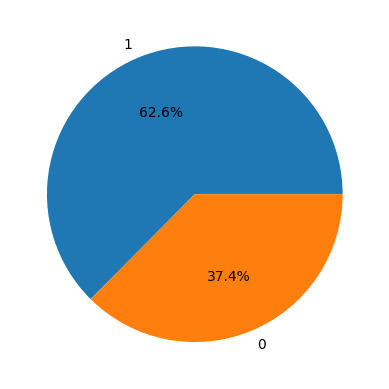

In [16]:
pie(train,'is_delayed')

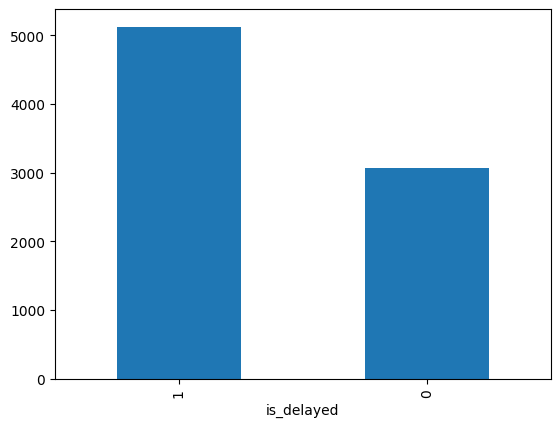

In [17]:
bar(train,'is_delayed')

#### Insights

> Berdasarkan distribusi kelas di atas, dapat dilihat bahwa data is_delayed bernilai 1 (terlambat) lebih banyak dibandingkan data is_delayed yang bernilai 0 (tidak terlambat).

#### Pertanyaan

> Apakah macro F1-score cocok untuk distribusi kelas ini? Bagaimana jika diganti dengan accuracy?

> Ya, macro F1-score cocok untuk distribusi kelas ini. Macro F1-score menghitung rata-rata F1-score dari setiap kelas, sehingga tidak terpengaruh oleh distribusi kelas yang tidak merata/seimbang. Jika diganti dengan accuracy, model mungkin bisa memiliki akurasi tinggi tetapi gagal mengklasifikasikan kelas minoritas dengan baik.

#### Pertanyaan

> Apakah pie chart atau bar chart lebih tepat untuk menampilkan distribusi kelas ini? Bagaimana jika jumlah kelasnya lebih banyak?

> Menurut kami, bar chart lebih tepat digunakan untuk menampilkan distribusi kelas ini karena secara visual lebih mudah untuk dilihat perbandingan kelasnya. Jika jumlah kelasnya lebih banyak, maka pie chart akan sulit untuk dilihat perbandingan kelasnya, karena slicenya semakin banyak dan semakin kecil (padat).

## Feature Analysis

In [18]:
display(train.dtypes)

id                     object
fulfillment_hub        object
delivery_service       object
item_tier              object
item_price_idr        float64
discount_idr            int64
billable_weight_kg    float64
previous_orders         int64
support_contacts        int64
customer_score        float64
customer_gender        object
is_delayed              int64
dtype: object

In [19]:
num_col = ['item_price_idr', 'discount_idr', 'billable_weight_kg', 'previous_orders', 'support_contacts', 'customer_score']
cat_col = ['id', 'fulfillment_hub', 'delivery_service', 'item_tier', 'customer_gender']

Statistik ringkas (describe)

In [20]:
train.describe()

,item_price_idr,discount_idr,billable_weight_kg,previous_orders,support_contacts,customer_score,is_delayed
count,7.884000e+03,8189.000000,8010.000000,8189.000000,8189.000000,7665.000000,8189.000000
mean,2.201519e+05,20066.833557,4.632452,3.569056,4.055807,3.000783,0.625595
std,1.493064e+05,24320.722828,2.200919,1.512051,1.143229,1.409037,0.483998
min,9.590000e+04,1200.000000,0.000000,2.000000,2.000000,1.000000,0.000000
25%,1.698000e+05,5900.000000,2.330000,3.000000,3.000000,2.000000,0.000000
50%,2.158000e+05,10600.000000,5.360000,3.000000,4.000000,3.000000,1.000000
75%,2.512000e+05,15200.000000,6.530000,4.000000,5.000000,4.000000,1.000000
max,2.749900e+06,97800.000000,10.200000,10.000000,7.000000,5.000000,1.000000


`histogram` dan `boxplot` menggambar distribusi fitur numerik dalam grid tiga kolom.

- `columns` berisi satu nama kolom atau daftar kolom, misalnya `num_col`
- `by` berisi kolom pemisah kelompok, misalnya `Settings.TARGET`, atau `None`
- `bins` berisi jumlah bin histogram, dengan nilai bawaan `30`
- `data` berisi DataFrame selain `train`, dengan nilai bawaan `None`

In [21]:
def as_list(columns):
    return [columns] if isinstance(columns, str) else list(columns)

def make_axes(count, ncols=3):
    nrows = -(-count // ncols)
    figure, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows), squeeze=False)

    for axis in axes.flat[count:]:
        axis.axis('off')

    return axes.flat[:count]

def histogram(columns, by=None, bins=30, data=None):
    frame = train if data is None else data

    for axis, column in zip(make_axes(len(as_list(columns))), as_list(columns)):
        edges = np.histogram_bin_edges(frame[column].dropna(), bins=bins)

        if by is None:
            axis.hist(frame[column].dropna(), bins=edges)
        else:
            for label, group in frame.groupby(by):
                axis.hist(group[column].dropna(), bins=edges, alpha=0.5, label=str(label))

            axis.legend(title=by)

        axis.set_title(column)

    plt.tight_layout()
    plt.show()

def boxplot(columns, by=None, data=None):
    frame = train if data is None else data

    for axis, column in zip(make_axes(len(as_list(columns))), as_list(columns)):
        if by is None:
            axis.boxplot(frame[column].dropna())
            axis.set_xticks([])
        else:
            groups = list(frame.groupby(by)[column])
            axis.boxplot([values.dropna() for _, values in groups])
            axis.set_xticks(range(1, len(groups) + 1), [str(label) for label, _ in groups])

        axis.set_title(column)

    plt.tight_layout()
    plt.show()

Distribusi fitur numerik.

<!-- Use bins 45 -->

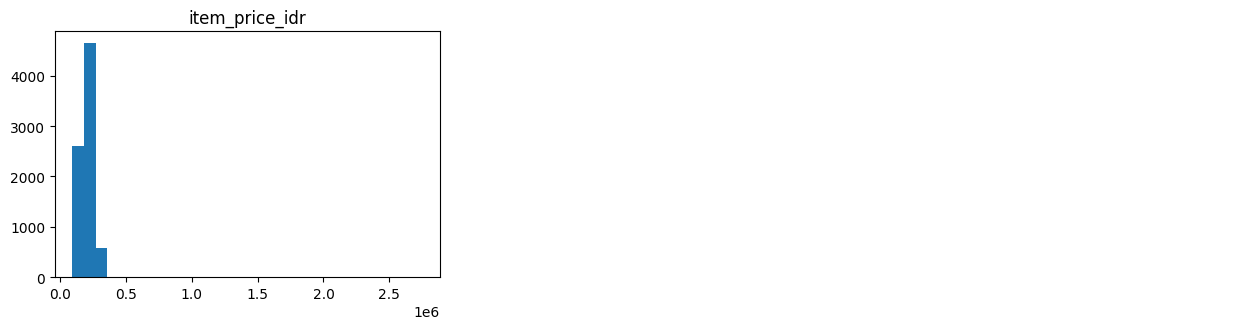

None

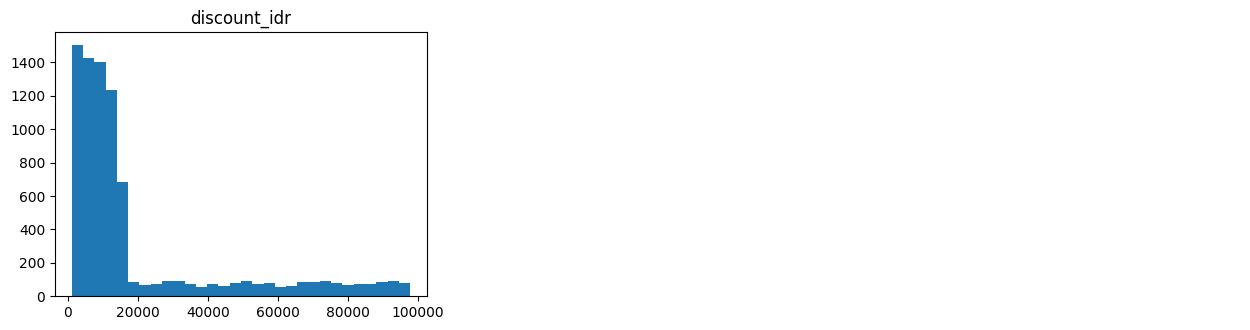

None

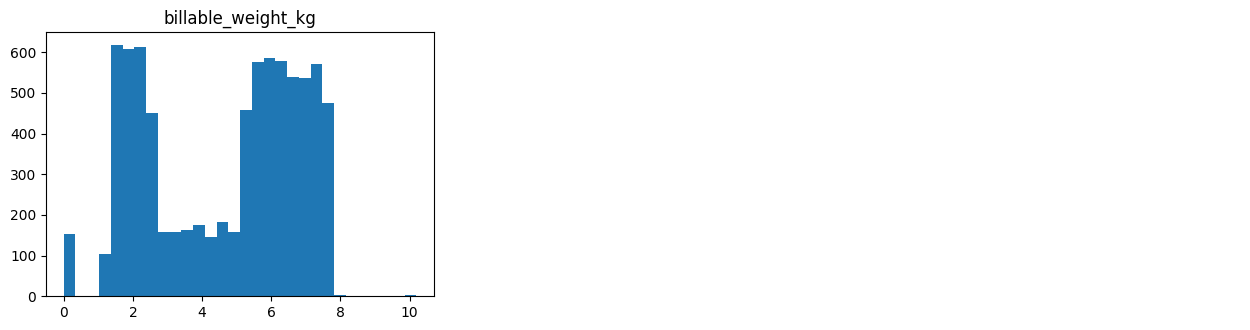

None

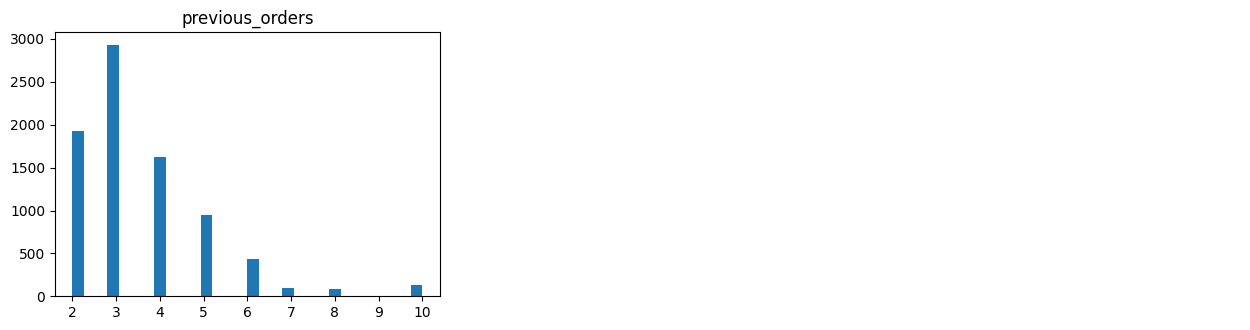

None

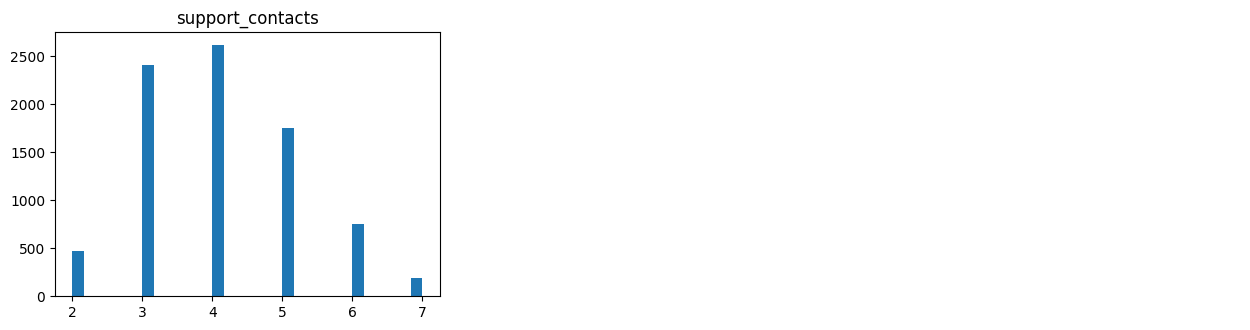

None

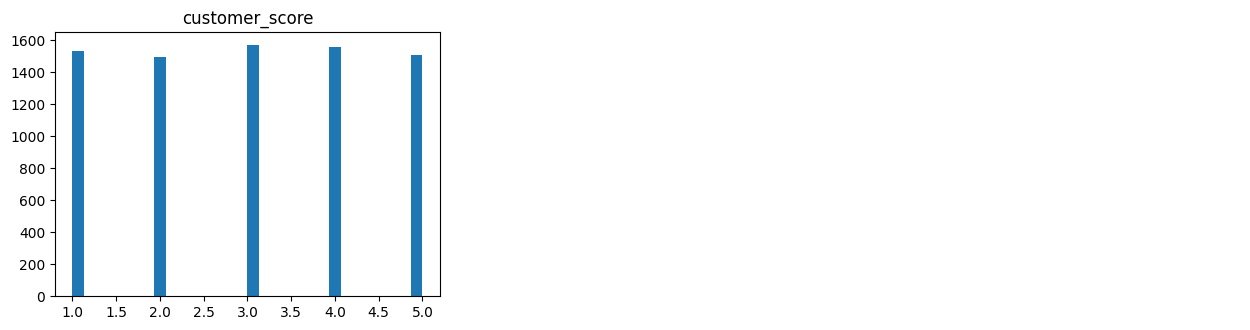

None

In [22]:
for col in num_col:
    display(histogram(col, None, 30, None))
    

Pengecekan outlier.

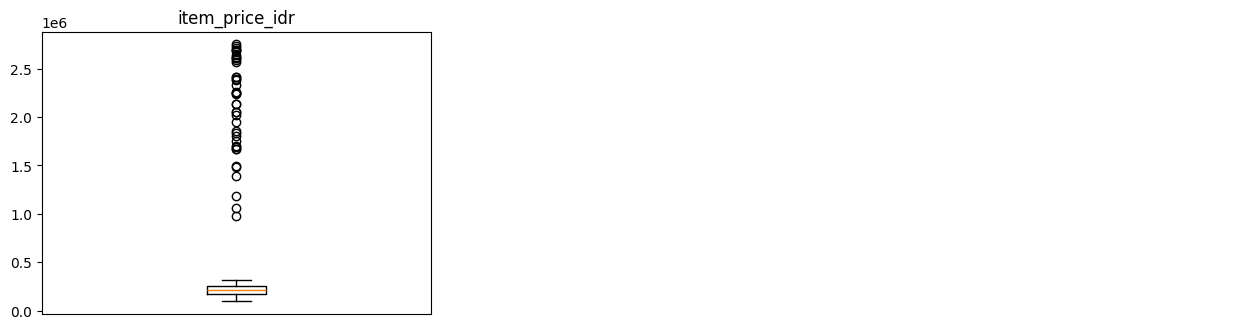

None

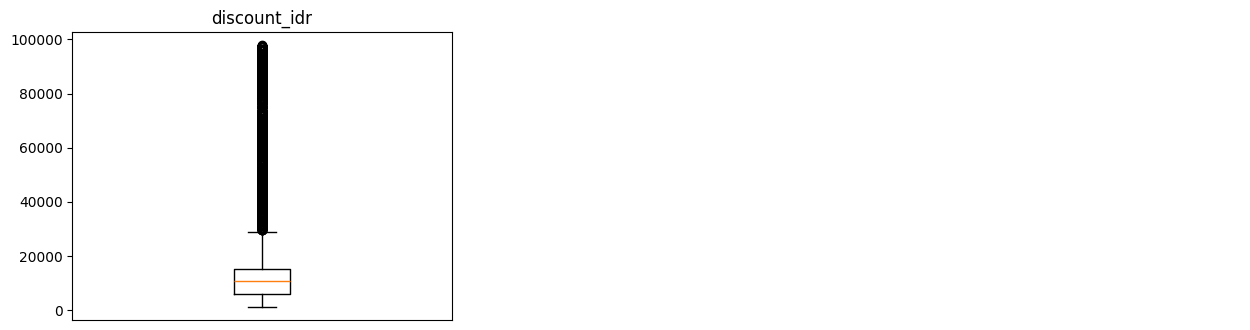

None

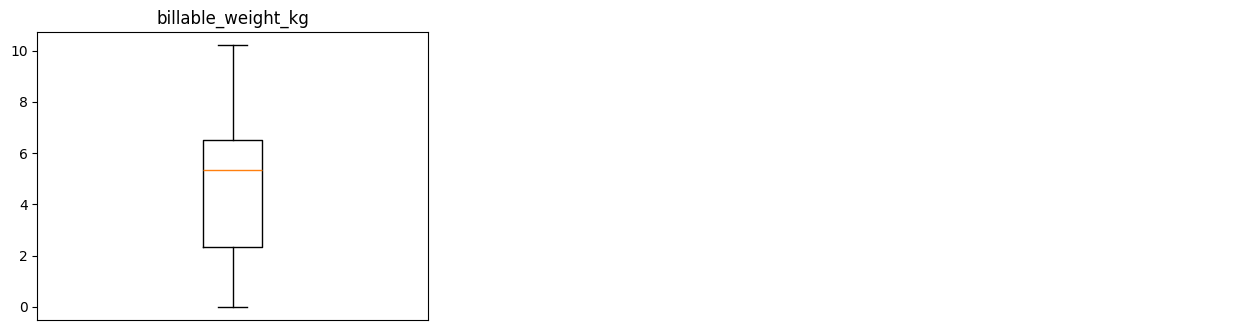

None

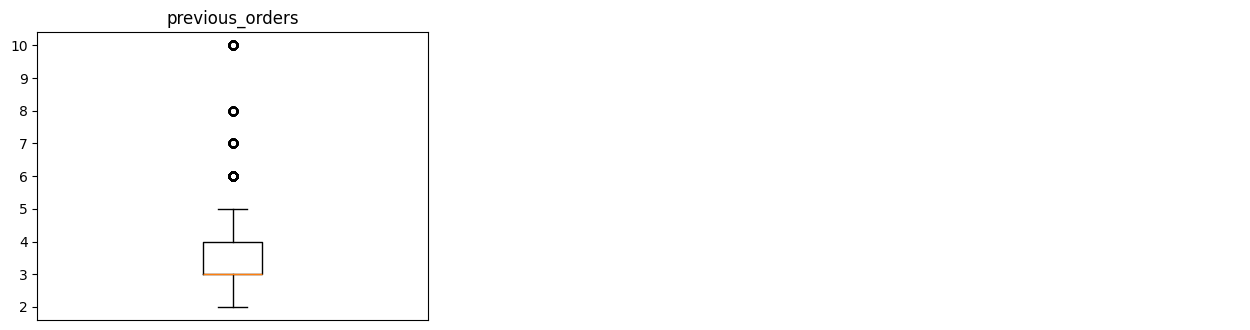

None

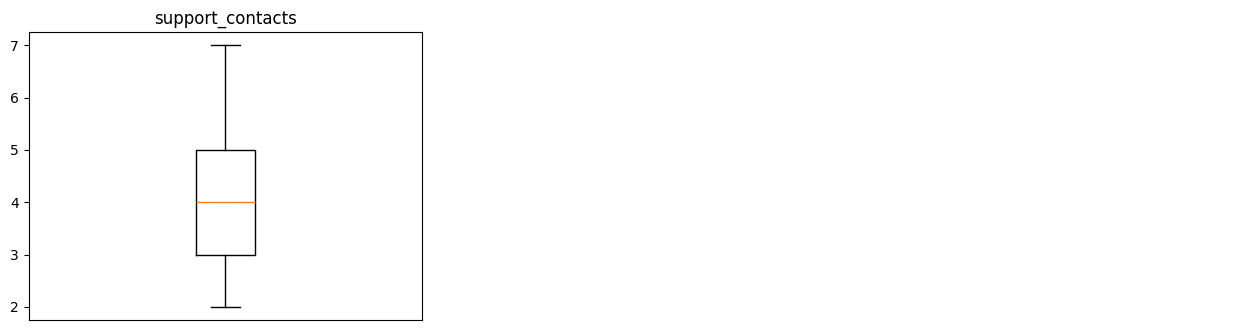

None

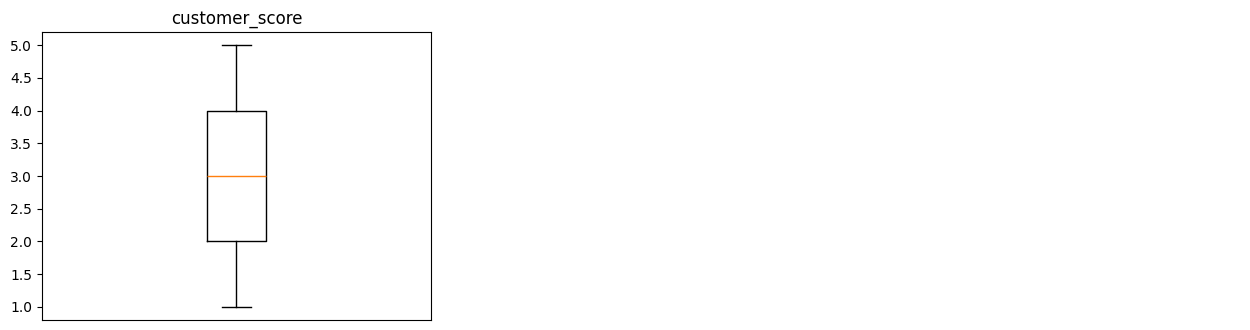

None

In [23]:
for col in num_col:
    display(boxplot(col, None, None))

#### Insights

> Berdasarkan boxplot, terdapat 3 kelas yang terdeteksi outlier, yaitu atribut discount_idr, item_price_idr, dan previous_orders. Pada atribut discount_idr, distribusi kelas condong ke kiri, sehingga pada box plot nilai discount lebih besar dari 20000 dianggap sebagai outlier. Pada atribut previous_orders, outlier terdeteksi pada kelas 6-10. Sedangkan pada item_price_idr, 0.5-2.5 karena barang dengan harga yang tinggi cukup jarang ditemui (kebanyakan barang berada pada rentang harga di bawah 0.5*1e6 rupiah)

Hubungan fitur dengan `is_delayed`.

- `target_rate(df, columns)` menggambar rate `is_delayed` untuk setiap kategori dalam grid dua kolom
- `correlation(df)` menghitung korelasi fitur numerik dengan `is_delayed`, terurut dari nilai absolut terbesar

In [24]:
def target_rate(df, columns):
    for axis, column in zip(make_axes(len(as_list(columns)), ncols=2), as_list(columns)):
        df.groupby(column)[Settings.TARGET].mean().plot.bar(ax=axis)
        axis.set_title(column)
        axis.set_ylabel(f'rate {Settings.TARGET}')

    plt.tight_layout()
    plt.show()

def correlation(df):
    numbers = df.select_dtypes('number').drop(columns=[Settings.TARGET])
    values = numbers.corrwith(df[Settings.TARGET])

    return values.reindex(values.abs().sort_values(ascending=False).index)

Rate `is_delayed` untuk setiap kategori.

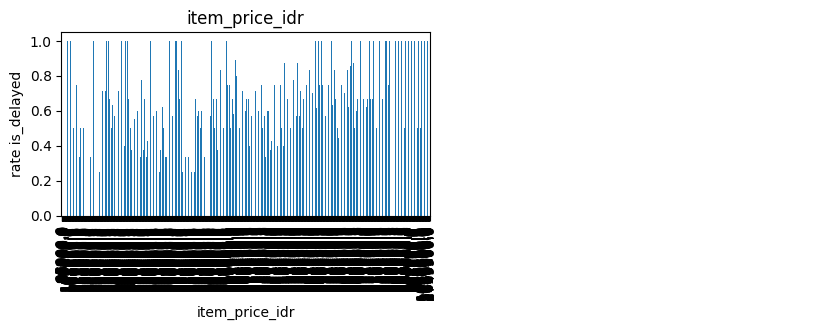

None

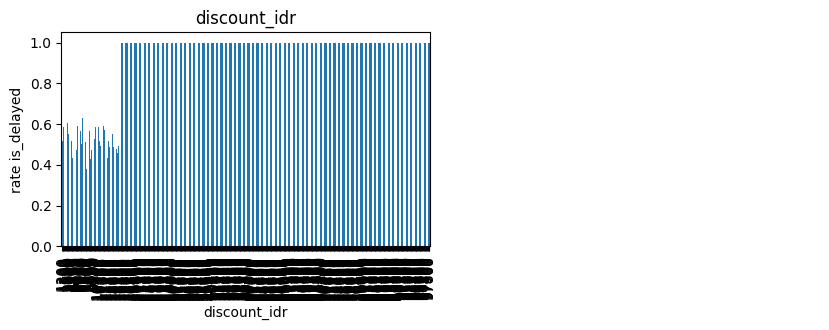

None

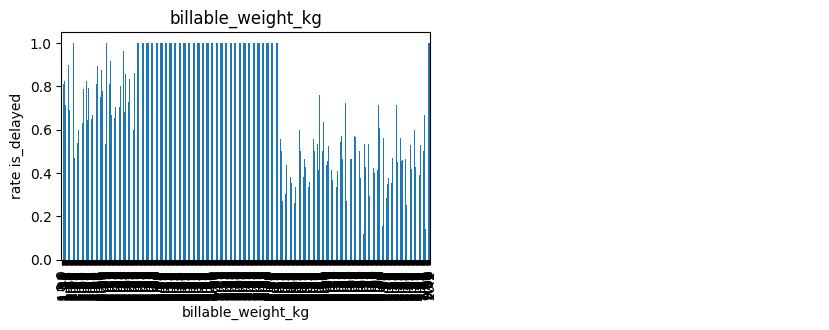

None

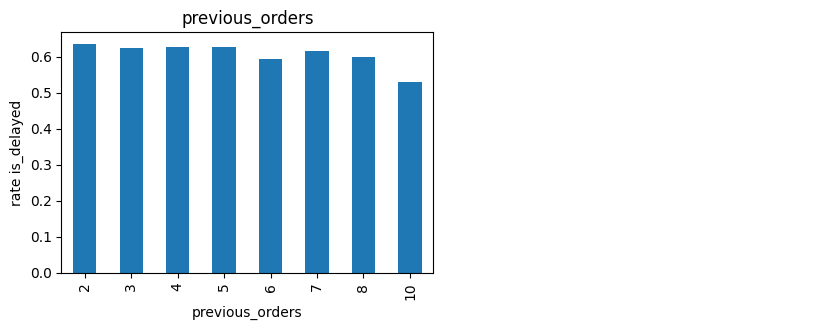

None

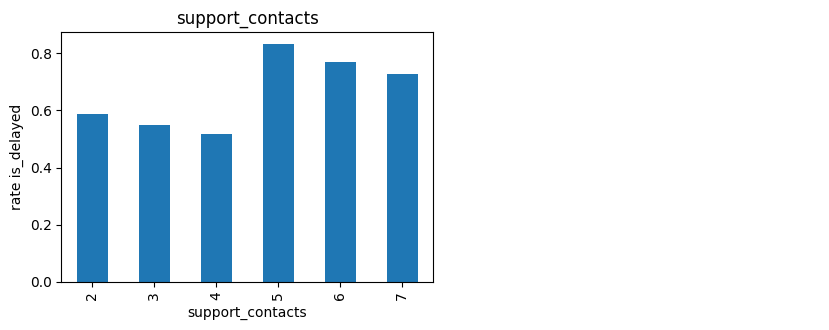

None

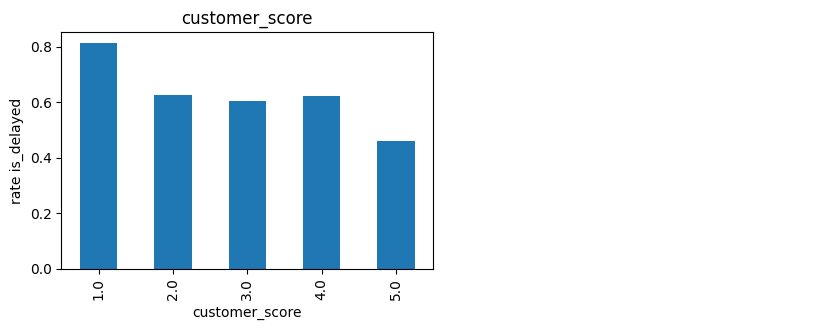

None

In [25]:
for col in num_col:
    display(target_rate(train, col))

Korelasi fitur numerik dengan `is_delayed`.

In [26]:
display(correlation(train))

discount_idr          0.373581
billable_weight_kg   -0.297423
customer_score       -0.206201
support_contacts      0.189181
item_price_idr        0.035625
previous_orders      -0.024744
dtype: float64

#### Insights

> Rate pada setiap kolom : 
- item_price_idr : rate untuk is_delayed bernilai 1 cukup acak 
- discount_idr: dengan discount besar, rate menjadi is_delayed menjadi besar (=1), tetapi hal ini bisa diakibatkan oleh frekuensi dari discount besar itu yang cukup jarang
- billable_weight_k : 
- previous_order : tidak ada pattern is_delayed pada kolom Insights
- supports_contract : dengan nilai 5, is_delayed paling tinggi
- customer_score : is_delayed mengakibat rating dari pelanggan menurun

---

# Data Cleaning and Preprocessing <a name="4"></a>

---

Data dibagi sebelum preprocessing. Setiap langkah di-fit hanya pada `X_train`, lalu diterapkan pada `X_train`, `X_val`, dan `X_test`.

## Data Split

Pembagian `train` menjadi `X_train` dan `X_val`.

- `X` berisi fitur `train` tanpa kolom `id` dan `is_delayed`
- `y` berisi kolom `is_delayed`
- `X_test` berisi fitur `test` tanpa kolom `id`

In [27]:
train.dtypes

id                     object
fulfillment_hub        object
delivery_service       object
item_tier              object
item_price_idr        float64
discount_idr            int64
billable_weight_kg    float64
previous_orders         int64
support_contacts        int64
customer_score        float64
customer_gender        object
is_delayed              int64
dtype: object

In [28]:
test.dtypes

id                     object
fulfillment_hub        object
delivery_service       object
item_tier              object
item_price_idr        float64
discount_idr            int64
billable_weight_kg    float64
previous_orders         int64
support_contacts        int64
customer_score        float64
customer_gender        object
dtype: object

In [29]:
X = train.drop(columns=['id', 'is_delayed']).copy()
y = train[['is_delayed']].copy()

X_test = test.drop(columns=['id']).copy()
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=Settings.TEST_SIZE, stratify=y, random_state=Settings.SEED
)

pd.Series({'X_train': len(X_train), 'X_val': len(X_val), 'X_test': len(X_test)})

X_train    6551
X_val      1638
X_test     2048
dtype: int64

#### Pertanyaan

> Apakah preprocessing boleh di-fit pada seluruh `train` sebelum dibagi? Bagaimana dampaknya terhadap skor validasi?

> Preprocessing tidak boleh di-fit pada seluruh data `train` sebelum dibagi karena validation akan mensimulasikan test sehingga pada data train sebisa mungkin tidak terlalu clean. Karena data test belum tentu clean dan bisa jadi ada value yang jauh dari data train.

#### Pertanyaan

> Apa pengaruh `stratify=y` pada pembagian data? Bagaimana jika parameter tersebut tidak dipakai?

> Pengaruh `startify=y` pada pembagian data adalah stratify membuat proporsi setiap kelas di train dan validation tetap sama. Tanpa stratify, kelas kecil dapat tidak terwakili di validaation dan membuat makro F1 menjadi tidak stabil.

## Duplicate

Baris duplikat pada `X_train` dapat dihapus beserta `y_train` atau dibiarkan. Baris pada `X_val` dan `X_test` tidak dihapus.

In [30]:
# Langkah ini boleh dilewati dengan menyertakan justifikasi
x_train_col = X_train.columns.tolist()
display(X_train.duplicated())
# for col in x_train_col:
#     display(X_train[col].duplicated())
# skip

6780    False
2699    False
3631    False
7671    False
8129    False
        ...  
6380    False
1570    False
3786    False
991     False
6306    False
Length: 6551, dtype: bool

#### Keputusan
Langkah ini dapat dilewati saja, karena tidak ada data yang terduplikasi pada data train.

## Missing Value dan Nilai Janggal

Nilai 0 pada `billable_weight_kg` dapat dijadikan missing value atau dibiarkan. Missing value dapat diimputasi dengan median atau modus, atau barisnya dihapus dari `X_train` beserta `y_train`. Baris pada `X_test` tidak dapat dihapus.

`impute` melakukan fit pada `X_train`, lalu mengisi missing value pada `X_train`, `X_val`, dan `X_test`.

- `columns` berisi satu kolom atau daftar kolom
- `strategy` bernilai `'mean'`, `'median'`, `'most_frequent'`, atau `'constant'`
- `zero_is_missing=True` mengubah nilai 0 menjadi missing value sebelum imputasi

In [31]:
def impute(columns, strategy='median', zero_is_missing=False):
    columns = as_list(columns)
    frames = [X_train, X_val, X_test]

    if zero_is_missing:
        for frame in frames:
            frame[columns] = frame[columns].replace(0, np.nan)

    imputer = SimpleImputer(strategy=strategy).fit(X_train[columns])

    for frame in frames:
        frame[columns] = imputer.transform(frame[columns])

In [32]:
impute("item_price_idr", 'mean', False)
impute("billable_weight_kg", 'mean', True)
impute("customer_score", 'mean', False)
impute("item_tier", 'most_frequent', False)

#### Keputusan

> Nilai 0 pada billable_weight_kg diperlakukan sebagai missing_value karena nilai 0 berarti berat tagihan tidak tercatat padahal seharusnya setiap tagihan memiliki berat (>0). Strategi yang digunakan adalah dengan mengisi nilai hilang dengan rata-rata (`mean`) agar tidak merusak distribusi kelas.

## Feature Engineering

Fitur baru dibentuk di dalam `engineer`, yang menerima satu DataFrame dan mengembalikan DataFrame. Logika di dalamnya bebas, selama hanya memakai kolom pada baris itu sendiri sehingga sama untuk `X_train`, `X_val`, dan `X_test`.

In [33]:
def engineer(df):
    df = df.copy()

    return df

In [34]:
# Langkah ini boleh dilewati dengan menyertakan justifikasi

#### Keputusan

> Tidak perlu membuat fitur baru karena data memiliki kolinearitas yang tinggi dan pola data sudah dapat diketahui.

## Outlier

Pilihan penanganan meliputi capping dengan batas IQR dari `X_train`, `RobustScaler` pada tahap scaling, atau membiarkan outlier.

`cap_outliers` menghitung batas IQR dari `X_train`, lalu memotong nilai pada `X_train`, `X_val`, dan `X_test`.

- `columns` berisi kolom numerik yang dipotong
- `factor` mengatur lebar batas IQR, dengan nilai bawaan `1.5`

<!-- Use factor 1.7 -->

In [35]:
def cap_outliers(columns, factor=1.5):
    columns = as_list(columns)
    q1, q3 = X_train[columns].quantile(0.25), X_train[columns].quantile(0.75)
    lower, upper = q1 - factor * (q3 - q1), q3 + factor * (q3 - q1)

    for frame in [X_train, X_val, X_test]:
        frame[columns] = frame[columns].clip(lower, upper, axis=1)

In [36]:
# Langkah ini boleh dilewati dengan menyertakan justifikasi


#### Keputusan

> Outlier tidak perlu didrop, karena outlier pada discount, price masih merupakan nilai yang wajar untuk kategori discount atau price. Teridentifikasi outlier karena memiliki frekuensi yang lebih sedikit dibandingkan dengan value data lainnya.

## Encoding

Fitur kategorikal diubah menjadi angka dengan one-hot atau ordinal encoding.

`encode` melakukan fit pada `X_train`, lalu mengganti kolom kategorikal pada `X_train`, `X_val`, dan `X_test`.

- `columns` berisi kolom kategorikal
- `kind` bernilai `'onehot'` atau `'ordinal'`
- `order` berisi urutan kategori untuk `'ordinal'`, misalnya `order=['Low', 'Medium', 'High']`

In [37]:
def encode(columns, kind='onehot', order=None):
    columns = as_list(columns)

    if kind == 'onehot':
        encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    else:
        categories = [order] * len(columns) if order else 'auto'
        encoder = OrdinalEncoder(categories=categories)

    encoder.fit(X_train[columns])
    names = list(encoder.get_feature_names_out(columns))

    for frame in [X_train, X_val, X_test]:
        encoded = encoder.transform(frame[columns])
        frame.drop(columns=columns, inplace=True)
        frame[names] = encoded

In [38]:
display(cat_col)

['id', 'fulfillment_hub', 'delivery_service', 'item_tier', 'customer_gender']

In [39]:
categorical_col = ['fulfillment_hub', 'delivery_service', 'item_tier', 'customer_gender']

In [40]:
encode(categorical_col, None, None)
X_train.head()

,item_price_idr,discount_idr,billable_weight_kg,previous_orders,support_contacts,customer_score,fulfillment_hub,delivery_service,item_tier,customer_gender
6780,250900.0,14800,6.39,6,3,1.0,0.0,2.0,2.0,1.0
2699,298100.0,4600,1.31,4,6,5.0,3.0,2.0,0.0,1.0
3631,161300.0,8700,7.23,6,4,3.0,3.0,2.0,0.0,1.0
7671,256100.0,15100,1.73,5,5,5.0,0.0,2.0,0.0,0.0
8129,212900.0,13500,7.18,3,5,2.0,3.0,2.0,0.0,1.0


#### Pertanyaan

> Apakah `item_tier` dan `fulfillment_hub` cocok di-encode dengan cara yang sama? Bagaimana jika keduanya di-encode secara ordinal?

> Ya, item_tier dan fulfillment_hub cocok di-encode dengan cara yang sama, karena keduanya berjenis kategorikal dengan data yang ordinal. Keduanya cocok di-encode secara ordinal, karena kedua atribut memiliki nilai ordinal.

## Scaling

Pilihan scaler meliputi `StandardScaler`, `MinMaxScaler`, `RobustScaler`, atau tanpa scaling.

`scale` melakukan fit pada `X_train`, lalu mengubah skala kolom pada `X_train`, `X_val`, dan `X_test`.

- `columns` berisi kolom numerik
- `kind` bernilai `'standard'`, `'minmax'`, atau `'robust'`

In [41]:
def scale(columns, kind='standard'):
    columns = as_list(columns)
    scalers = {'standard': StandardScaler, 'minmax': MinMaxScaler, 'robust': RobustScaler}
    scaler = scalers[kind]().fit(X_train[columns])

    for frame in [X_train, X_val, X_test]:
        frame[columns] = scaler.transform(frame[columns])

In [42]:
# Langkah ini boleh dilewati dengan menyertakan justifikasi

#### Keputusan

> Langkah scale dilewati karena scaling sudah dilakukan dengan StandardScaler di dalam pipeline make_model, sehingga berlaku untuk kelima model. Dengan pipeline, scaler di-fit ulang hanya pada bagian latih setiap kali model dilatih, termasuk pada setiap fold K-Fold.

#### Pertanyaan

> Apakah kelima model membutuhkan scaling? Bagaimana jika scaling tidak dilakukan?

> Tidak semuanya. KNN dan SVM membutuhkan scaling karena keduanya bekerja dengan jarak atau kernel. Tanpa scaling, fitur berskala besar mendominasi perhitungan jarak, sedangkan fitur kecil hampir diabaikan. Logistic regression juga membutuhkan scaling agar regularisasi adil untuk setiap fitur agar solver konvergen. Sedangkan Decision Tree dan Gaussian NB tidak membutuhkan scaling karena split hanya bergantung pada urutan nilai dalam satu fitur, serta mean dan variansi dihitung per fitur secara terpisah. 

---

# Modeling and Validation <a name="5"></a>

---

Baseline kelima model dan submisi pertama sebelum tuning.

## Class Imbalance

Pilihan penanganan meliputi tanpa penanganan, `class_weight='balanced'` pada model yang mendukungnya, SMOTE, atau random undersampling. Resampling hanya diterapkan pada data latih.

`resample` menyeimbangkan kelas pada data latih. Metode yang dipilih disimpan pada variabel `method`.

- `method` bernilai `None`, `'smote'`, atau `'undersample'`
- `class_weight='balanced'` diatur langsung pada definisi model yang mendukungnya

In [43]:
def resample(X, y, method=None):
    if method is None:
        return X, y

    samplers = {'smote': SMOTE, 'undersample': RandomUnderSampler}

    return samplers[method](random_state=Settings.SEED).fit_resample(X, y)

In [44]:
# check class imbalance
print(y_train.value_counts(normalize=True))

is_delayed
1             0.625553
0             0.374447
Name: proportion, dtype: float64


In [45]:
# Langkah ini boleh dilewati dengan menyertakan justifikasi

#### Keputusan

> Tidak dilakukan resampling pada data latih karena class imbalance masih sangat minimal, dan ketika ditinjau itu ketidakseimbangannya terletak pada jumlah kelas is_delayed=0 dan jumlah kelas is_delayed=0, which is menurut kami aman-aman saja kak. 

#### Pertanyaan

> Apakah SMOTE boleh diterapkan sebelum data dibagi? Bagaimana dampaknya terhadap skor validasi?

> Tidak boleh, karena resampling hanya diterapkan pada data latih sehingga tidak boleh diterapkan setelah data dibagi menjadi data latih sesungguhnya dan data validasi.

In [46]:
from sklearn.pipeline import Pipeline

def make_model(estimator):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('scaler', StandardScaler()),                           
        ('model', estimator),
    ])

## KNN

Model K-Nearest Neighbors pada variabel `knn`.

<!-- Use n_neighbors 17 -->

In [47]:
knn = make_model(KNeighborsClassifier())
display(knn)

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('scaler', StandardScaler()),
                ('model', KNeighborsClassifier())])

## DTL

Model Decision Tree pada variabel `dtl`.

In [48]:
dtl = make_model(DecisionTreeClassifier(random_state=Settings.SEED))
display(dtl)

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('scaler', StandardScaler()),
                ('model', DecisionTreeClassifier(random_state=42))])

## SVM

Model Support Vector Machine pada variabel `svc`.

In [49]:
svc = make_model(SVC(random_state=Settings.SEED))
svc

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('scaler', StandardScaler()), ('model', SVC(random_state=42))])

## Logistic Regression

Model Logistic Regression pada variabel `lr`.

In [50]:
lr = make_model(LogisticRegression(solver='saga', random_state=Settings.SEED))
lr

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('scaler', StandardScaler()),
                ('model', LogisticRegression(random_state=42, solver='saga'))])

## Gaussian NB

Model Gaussian Naive Bayes pada variabel `gnb`.

In [51]:
gnb = make_model(GaussianNB())
gnb


Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('scaler', StandardScaler()), ('model', GaussianNB())])

## Validation

Holdout melatih model pada `X_train` dan mengukurnya pada `X_val`. K-Fold hanya memakai `X_train`. Metrik yang dipakai adalah macro F1-score.

Kelima model dikumpulkan pada `models`.

In [52]:
models = {'knn': knn, 'dtl': dtl, 'svc': svc, 'lr': lr, 'gnb': gnb}
models

{'knn': Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                 ('scaler', StandardScaler()),
                 ('model', KNeighborsClassifier())]),
 'dtl': Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                 ('scaler', StandardScaler()),
                 ('model', DecisionTreeClassifier(random_state=42))]),
 'svc': Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                 ('scaler', StandardScaler()), ('model', SVC(random_state=42))]),
 'lr': Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                 ('scaler', StandardScaler()),
                 ('model', LogisticRegression(random_state=42, solver='saga'))]),
 'gnb': Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                 ('scaler', StandardScaler()), ('model', GaussianNB())])}

## Model Comparison

Perbandingan hasil validasi kelima model.

Holdout Method. `holdout` melatih setiap model pada `X_train` dan mengukurnya pada `X_val`.

- `models` berisi dictionary nama dan model, misalnya `models`
- `method` sama seperti pada `resample`

In [53]:
def fit_predict(model, X_fit, y_fit, X_eval, method=None):
    X_resampled, y_resampled = resample(X_fit, y_fit, method)

    return clone(model).fit(X_resampled, y_resampled).predict(X_eval)

def holdout(models, X_train, y_train, X_val, y_val, method=None):
    scores = {}

    for name, model in models.items():
        predicted = fit_predict(model, X_train, y_train, X_val, method)
        scores[name] = f1_score(y_val, predicted, average='macro')

    return pd.Series(scores, name='holdout').to_frame()

In [54]:
holdout_table = holdout(models, X_train, y_train, X_val, y_val, method=None)
holdout_table

/root/venv/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for examp

,holdout
knn,0.775085
dtl,0.791641
svc,0.829559
lr,0.734195
gnb,0.684613


In [55]:
fit_predict(knn, X_train, y_train, X_val, method=None)
fit_predict(dtl, X_train, y_train, X_val, method=None)
fit_predict(svc, X_train, y_train, X_val, method=None)
fit_predict(lr, X_train, y_train, X_val, method=None)
fit_predict(gnb, X_train, y_train, X_val, method=None)

/root/venv/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for examp

array([0, 1, 1, ..., 0, 0, 0], shape=(1638,))

K-Fold Cross Validation. `kfold` menghitung rata-rata dan simpangan baku skor K-Fold setiap model.

- `models` berisi dictionary nama dan model
- `X` dan `y` berisi data latih, misalnya `X_train` dan `y_train`
- `method` sama seperti pada `resample`

In [56]:
def kfold_scores(model, X, y, method=None):
    folds = StratifiedKFold(n_splits=Settings.N_FOLDS, shuffle=True, random_state=Settings.SEED)
    scores = []


    for fit_index, eval_index in folds.split(X, y):
        predicted = fit_predict(model, X.iloc[fit_index], y.iloc[fit_index], X.iloc[eval_index], method)
        scores.append(f1_score(y.iloc[eval_index], predicted, average='macro'))

    return np.array(scores)

def kfold(models, X, y, method=None):
    rows = {}

    for name, model in models.items():
        scores = kfold_scores(model, X, y, method)
        rows[name] = {'kfold_mean': scores.mean(), 'kfold_std': scores.std()}

    return pd.DataFrame(rows).T

In [57]:
kfold_table = kfold(models, X_train, y_train, method=None)
kfold_table

/root/venv/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/root/venv/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/root/venv/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/root/venv/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for 

,kfold_mean,kfold_std
knn,0.776751,0.005728
dtl,0.803171,0.008648
svc,0.833673,0.012249
lr,0.736250,0.018907
gnb,0.691618,0.008105


Tabel perbandingan. `compare` menggabungkan tabel holdout dan K-Fold, lalu mengurutkannya dari `kfold_mean` tertinggi.

In [58]:
def compare(holdout_table, kfold_table):
    return holdout_table.join(kfold_table).sort_values('kfold_mean', ascending=False)

In [59]:
compare(holdout_table, kfold_table)

,holdout,kfold_mean,kfold_std
svc,0.829559,0.833673,0.012249
dtl,0.791641,0.803171,0.008648
knn,0.775085,0.776751,0.005728
lr,0.734195,0.736250,0.018907
gnb,0.684613,0.691618,0.008105


#### Insights

> SVM menjadi baseline terbaik (K-Fold ~0,834; holdout ~0,830), diikuti Decision Tree (~0,803), KNN (~0,777), Logistic Regression (~0,736), dan Gaussian NB (~0,692). SVM (kernel RBF) dan Decision Tree unggul karena mampu membentuk batas keputusan tidak linear, sesuai temuan EDA bahwa discount_idr berpengaruh secara ambang dan billable_weight_kg tidak monoton. Decision Tree tanpa batasan kedalaman rentan overfitting sehingga skornya berpotensi naik setelah max_depth dan min_samples_leaf di-tuning, sementara KNN (n_neighbors = 5) masih sensitif terhadap noise dan perlu diuji dengan K serta metrik jarak lain. Logistic Regression terbatas pada batas linear, dan Gaussian NB paling buruk karena asumsi normalitas dan independensi fitur tidak sesuai dengan data yang banyak memuat fitur diskret/kategorikal dan distribusi billable_weight_kg yang bimodal. Hasil validasi tergolong stabil, dengan simpangan baku K-Fold ≤ 0,019 dan selisih holdout terhadap rata-rata K-Fold maksimal ±0,012 (Decision Tree).

#### Pertanyaan

> Apa yang berbeda dari skor holdout dan K-Fold? Skor mana yang dipakai untuk memilih model?

> Skor holdout berasal dari satu pembagian data, yaitu data latih pada X_train dan data uji pada X_val. Sedangkan skor K-Fold adalah rata-rata dari 5 fold pada X_train, di mana setiap sampel pernah menjadi data evaluasi dna simpangan bakunya menunjukkan seberapa stabil model terhadap perubahan data latih. Skor yang dipakai untuk memilih model adalah kfold_mean, karena estimasinya lebih stabil dan tidak bergantung pada satu split. Skor holdout dipakai sebagai pemeriksaan akhir pada data yang tidak dipakai saat memilih konfigurasi. 

## Feature Importance

Fitur yang paling membantu Decision Tree dan Logistic Regression membedakan kedua kelas.

`importance` mengurutkan feature importance atau koefisien berdasarkan nilai absolutnya.

- `model` berupa Decision Tree atau Logistic Regression
- `X` dan `y` berisi data latih, misalnya `X_train` dan `y_train`

In [60]:
def importance(model, X, y):
    fitted = clone(model).fit(X, y)
    values = fitted.feature_importances_ if hasattr(fitted, 'feature_importances_') else fitted.coef_[0]
    ranked = pd.Series(values, index=X.columns)

    return ranked.reindex(ranked.abs().sort_values(ascending=False).index)

Decision Tree.

In [61]:
prep = make_model('passthrough').fit(X_train)
X_train_scaled = pd.DataFrame(prep[:-1].transform(X_train), columns=X_train.columns, index=X_train.index)

importance(clone(dtl.named_steps['model']), X_train_scaled, y_train)

discount_idr          0.264879
item_price_idr        0.158621
support_contacts      0.140030
customer_score        0.121488
billable_weight_kg    0.119824
item_tier             0.091903
previous_orders       0.055377
fulfillment_hub       0.023750
customer_gender       0.012271
delivery_service      0.011857
dtype: float64

Logistic Regression.

In [62]:
importance(clone(lr.named_steps['model']), X_train_scaled, y_train)

/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


discount_idr          2.183546
support_contacts      0.650656
customer_score       -0.599806
item_tier             0.394949
billable_weight_kg   -0.315136
previous_orders      -0.167888
item_price_idr        0.116217
fulfillment_hub      -0.035466
delivery_service     -0.034964
customer_gender       0.020561
dtype: float64

#### Insights

> Decision Tree dan Logistic Regression sama-sama menunjukkan bahwa discount_idr adalah fitur paling berpengaruh, di mana semakin besar diskon, semakin besar kemungkinan pesanan terlambat. Fitur penting lainnya adalah support_contacts (semakin sering menghubungi layanan pelanggan, semakin mungkin terlambat), customer_score (skor tinggi cenderung tepat waktu), dan billable_weight_kg, sedangkan fulfillment_hub, delivery_service, dan customer_gender hampir tidak berpengaruh. Ada dua hal yang perlu dibaca hati-hati. Pertama, importance item_price_idr pada Decision Tree cukup tinggi padahal korelasinya dengan target hampir nol, kemungkinan karena pohon yang belum di-tuning memanfaatkan banyaknya nilai unik harga untuk menghafal noise. Kedua, koefisien billable_weight_kg pada Logistic Regression kecil karena hubungannya tidak monoton (berat menengah selalu terlambat) sehingga tidak bisa diwakili satu koefisien linear, dan koefisien item_tier kurang bermakna karena encoding ordinalnya mengikuti urutan alfabet (Basic, Premium, Standard), bukan tingkatan sebenarnya.

#### Pertanyaan

> Apakah kelima model memiliki feature importance? Bagaimana melihat pengaruh fitur pada model yang tidak memilikinya?

> Tidak semua model menyediakan feature importance secara langsung. Hanya Decision Tree (feature_importances_) dan Logistic Regression (coef_) yang memilikinya; SVM hanya punya coef_ jika kernelnya linear, sedangkan KNN dan Gaussian NB tidak punya sama sekali (theta_ dan var_ pada Gaussian NB hanyalah mean dan variansi per kelas, bukan ukuran pengaruh fitur). Untuk model-model tersebut, pengaruh fitur dapat diukur dengan metode model-agnostic, yaitu permutation importance (mengacak satu fitur pada data validasi lalu mengukur penurunan macro F1), drop-column importance (melatih ulang model tanpa satu fitur lalu membandingkan skornya), dan partial dependence plot atau SHAP untuk melihat arah dan bentuk pengaruh fitur terhadap prediksi.

#### Pertanyaan

> Apakah fitur dengan importance rendah perlu dibuang? Bagaimana dampaknya terhadap model?

> Fitur dengan importance rendah tidak harus dibuang, dan keputusannya sebaiknya diuji dengan validasi, karena fitur yang lemah pada satu model belum tentu tidak berguna bagi model lain atau saat dikombinasikan dengan fitur lain. Membuang fitur yang tidak informatif dapat membantu KNN dan SVM karena fitur noise tidak lagi ikut dihitung dalam jarak. Selain itu, membuang fitur yang tidak informatif juga dapat membuat model lebih sederhana dan cepat.

## Hyperparameter Tuning

Dikerjakan setelah submisi pertama. `tune` menampilkan skor K-Fold untuk setiap kombinasi parameter.

`tune` mencoba setiap kombinasi pada `grid` dan mengurutkannya dari skor tertinggi.

- `grid` berupa dictionary nama parameter dan daftar nilainya, misalnya `{'n_neighbors': [5, 15]}`
- `X`, `y`, dan `method` sama seperti pada `kfold`

In [63]:
def tune(model, grid, X, y, method=None):
    rows = []

    for params in ParameterGrid(grid):
        scores = kfold_scores(clone(model).set_params(**params), X, y, method)
        rows.append({**params, 'kfold_mean': scores.mean(), 'kfold_std': scores.std()})

    return pd.DataFrame(rows).sort_values('kfold_mean', ascending=False, ignore_index=True)

KNN dengan parameter yang umum di-tuning.

- `n_neighbors`, misalnya `[5, 15, 31, 51]`
- `metric` bernilai `'euclidean'`, `'manhattan'`, atau `'minkowski'`
- `weights` bernilai `'uniform'` atau `'distance'`

In [64]:
knn_grid = {
    'model__n_neighbors': [5, 15, 31, 51],
    'model__metric': ['euclidean', 'manhattan', 'minkowski'],
    'model__weights': ['uniform', 'distance'],
}
knn_results = tune(knn, knn_grid, X_train, y_train)
knn_results.head()

/root/venv/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/root/venv/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/root/venv/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/root/venv/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for 

,model__metric,model__n_neighbors,model__weights,kfold_mean,kfold_std
0,manhattan,51,distance,0.823546,0.009356
1,manhattan,31,distance,0.816643,0.006703
2,manhattan,31,uniform,0.813881,0.009656
3,manhattan,51,uniform,0.813788,0.010965
4,manhattan,15,distance,0.810446,0.008490


Decision Tree dengan parameter yang umum di-tuning.

- `max_depth`, misalnya `[4, 6, 8, None]`
- `min_samples_split`, misalnya `[2, 10, 20]`
- `min_samples_leaf`, misalnya `[1, 10, 30]`

In [65]:
dtl_grid = {
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [4, 6, 7, 8, None],
    'model__min_samples_split': [2, 20, 50],
    'model__min_samples_leaf': [5, 10, 20, 30],
}
dtl_results = tune(dtl, dtl_grid, X_train, y_train)
dtl_results.head()

,model__criterion,model__max_depth,model__min_samples_leaf,model__min_samples_split,kfold_mean,kfold_std
0,gini,7.0,20,20,0.891556,0.006590
1,gini,7.0,20,50,0.891556,0.006590
2,gini,7.0,20,2,0.891556,0.006590
3,gini,7.0,10,50,0.890907,0.006111
4,gini,8.0,20,50,0.890895,0.007475


SVM dengan parameter yang umum di-tuning.

- `kernel` bernilai `'rbf'`, `'linear'`, atau `'poly'`
- `C`, misalnya `[0.1, 1, 10]`
- `gamma`, misalnya `['scale', 0.01, 0.1]`

In [66]:
svc_grid = {
    'model__kernel': ['rbf', 'linear', 'poly'],
    'model__C': [0.1, 1, 10, 30],
    'model__gamma': ['scale', 0.01, 0.1],
}
svc_results = tune(svc, svc_grid, X_train, y_train)
svc_results.head()

/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for exam

,model__C,model__gamma,model__kernel,kfold_mean,kfold_std
0,10.0,0.1,rbf,0.850374,0.012393
1,10.0,scale,rbf,0.850374,0.012393
2,30.0,0.1,rbf,0.849481,0.008448
3,30.0,scale,rbf,0.849481,0.008448
4,1.0,0.1,rbf,0.833673,0.012249


Logistic Regression dengan parameter yang umum di-tuning.

- `max_iter`, misalnya `[500, 1000, 2000]`
- `penalty` bernilai `'l2'` atau `None`, sedangkan `'l1'` memerlukan `solver='liblinear'`
- `C`, misalnya `[0.01, 0.1, 1, 10]`

In [67]:
lr_grid = {
    'model__C': [0.01, 0.1, 1, 10],
    'model__penalty': ['l2', None],
    'model__max_iter': [500, 1000, 2000],
}
lr_results = tune(lr, lr_grid, X_train, y_train)
lr_results.head()

/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for exam

,model__C,model__max_iter,model__penalty,kfold_mean,kfold_std
0,0.1,500,l2,0.737532,0.019780
1,0.1,1000,l2,0.737532,0.019780
2,0.1,2000,l2,0.737532,0.019780
3,1.0,1000,l2,0.736250,0.018907
4,1.0,500,l2,0.736250,0.018907


Gaussian NB dengan parameter yang umum di-tuning.

- `var_smoothing`, misalnya `[1e-9, 1e-6, 1e-3]`

In [68]:
gnb_grid = {
    'model__var_smoothing': [1e-9, 1e-6, 1e-3, 1e-2, 1e-1],
}
gnb_results = tune(gnb, gnb_grid, X_train, y_train)
gnb_results.head()

/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for exam

,model__var_smoothing,kfold_mean,kfold_std
0,1.000000e-09,0.691618,0.008105
1,1.000000e-06,0.691618,0.008105
2,1.000000e-03,0.690858,0.008537
3,1.000000e-01,0.689171,0.009279
4,1.000000e-02,0.688904,0.008741


Model hasil tuning pada variabel `knn_tuned`, `dtl_tuned`, `svc_tuned`, `lr_tuned`, dan `gnb_tuned`.

In [69]:
knn_tuned = clone(knn).set_params(model__n_neighbors=51, model__metric='manhattan', model__weights='distance')
dtl_tuned = clone(dtl).set_params(model__criterion='gini', model__max_depth=7, model__min_samples_split=20, model__min_samples_leaf=20)
svc_tuned = clone(svc).set_params(model__kernel='rbf', model__C=10, model__gamma='scale')
lr_tuned = clone(lr).set_params(model__C=0.1, model__penalty='l2', model__max_iter=1000)
gnb_tuned = clone(gnb).set_params(model__var_smoothing=1e-9)

Kelima model hasil tuning dikumpulkan pada `tuned_models`. Hapus tanda komentar setelah seluruh model hasil tuning didefinisikan.

In [70]:
tuned_models = {'knn': knn_tuned, 'dtl': dtl_tuned, 'svc': svc_tuned, 'lr': lr_tuned, 'gnb': gnb_tuned}
tuned_models

{'knn': Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                 ('scaler', StandardScaler()),
                 ('model',
                  KNeighborsClassifier(metric='manhattan', n_neighbors=51,
                                       weights='distance'))]),
 'dtl': Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                 ('scaler', StandardScaler()),
                 ('model',
                  DecisionTreeClassifier(max_depth=7, min_samples_leaf=20,
                                         min_samples_split=20,
                                         random_state=42))]),
 'svc': Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                 ('scaler', StandardScaler()),
                 ('model', SVC(C=10, random_state=42))]),
 'lr': Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                 ('scaler', StandardScaler()),
                 ('model',
                  Logist

Perbandingan model hasil tuning.

In [71]:
holdout_tuned = holdout(tuned_models, X_train, y_train, X_val, y_val, method=None)
kfold_tuned = kfold(tuned_models, X_train, y_train, method=None)
tuned_table = compare(holdout_tuned, kfold_tuned)
tuned_table

/root/venv/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for examp

,holdout,kfold_mean,kfold_std
dtl,0.889675,0.891556,0.006590
svc,0.852974,0.850374,0.012393
knn,0.816090,0.823546,0.009356
lr,0.735531,0.737532,0.019780
gnb,0.684613,0.691618,0.008105


#### Insights

> Setelah tuning, Decision Tree menjadi model terbaik (K-Fold ±0,892; holdout ±0,890), naik ±0,088 dari baseline ±0,803 dengan max_depth=7 dan min_samples_leaf=20. Peningkatan ini terjadi karena pohon yang dibatasi tidak lagi menghafal noise dan cocok dengan pola data berupa beberapa ambang tegas (diskon besar, rentang berat, jumlah kontak layanan). SVM naik dari ±0,834 ke ±0,850 dengan C=10 karena batas keputusan menjadi lebih fleksibel, sedangkan KNN naik dari ±0,777 ke ±0,824 dengan n_neighbors=51, metric='manhattan', dan weights='distance', meski nilai K terbaik berada di ujung grid sehingga rentangnya sebaiknya diperluas. Logistic Regression (±0,738) dan Gaussian NB (±0,692) tidak berubah karena keterbatasannya terletak pada asumsi model. Skor holdout semua model dekat dengan rata-rata K-Fold (selisih ≤ 0,008), sehingga hasil tuning tidak overfit ke fold tertentu.

---

# Error Analysis <a name="6"></a>

---

Analisis kesalahan prediksi pada `X_val`.

## Confusion Matrix

Confusion matrix serta precision dan recall kelima model.

`confusion` menggambar confusion matrix setiap model dalam satu baris, sedangkan `report` menampilkan precision, recall, dan F1-score setiap model.

- `models` berisi dictionary model, misalnya `tuned_models`
- `method` sama seperti pada `resample`

In [72]:
def confusion(models, X_train, y_train, X_val, y_val, method=None):
    figure, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 3.6), squeeze=False)

    for axis, (name, model) in zip(axes.flat, models.items()):
        predicted = fit_predict(model, X_train, y_train, X_val, method)
        ConfusionMatrixDisplay.from_predictions(y_val, predicted, ax=axis, colorbar=False)
        axis.set_title(name)

    plt.tight_layout()
    plt.show()

def report(models, X_train, y_train, X_val, y_val, method=None):
    tables = {}

    for name, model in models.items():
        predicted = fit_predict(model, X_train, y_train, X_val, method)
        tables[name] = pd.DataFrame(classification_report(y_val, predicted, output_dict=True)).T

    return pd.concat(tables)

Confusion matrix.

/root/venv/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for examp

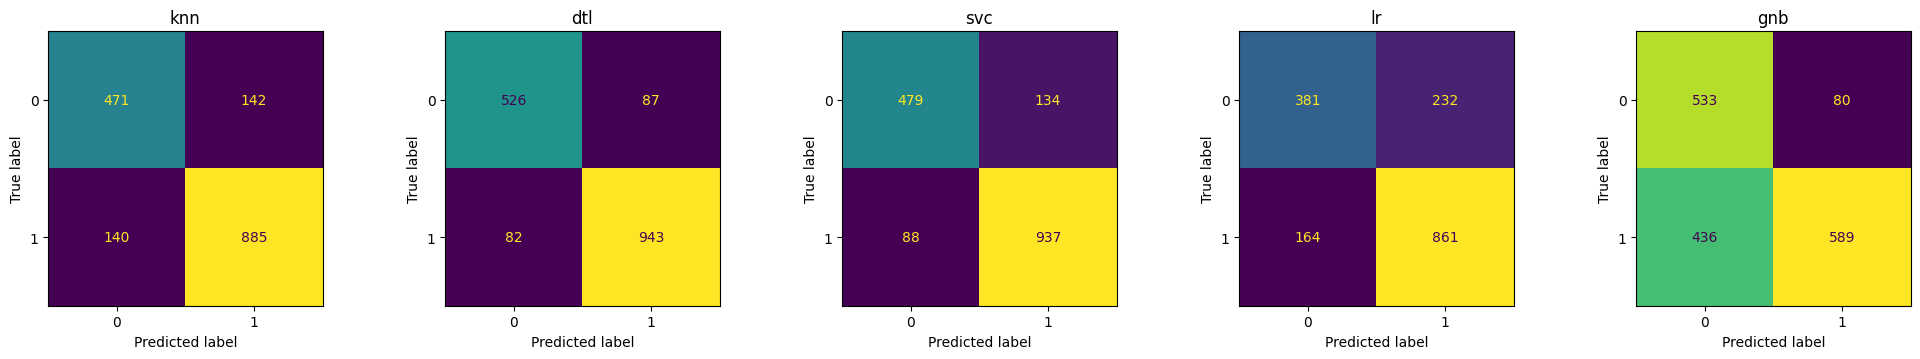

In [73]:
confusion(tuned_models, X_train, y_train, X_val, y_val, method=None)

#### Insights

> Decision Tree membuat kesalahan paling sedikit (169 dari 1.638) dengan pola seimbang, yaitu 87 pesanan tepat waktu diprediksi terlambat (*false positive*) dan 82 pesanan terlambat diprediksi tepat waktu (*false negative*). Lalu, SVM (134 FP, 88 FN) dan KNN (142 FP, 140 FN) lebih banyak salah, dengan SVM cenderung keliru menganggap pesanan tepat waktu sebagai terlambat. Sementara itu, Logistic Regression paling banyak salah pada pesanan tepat waktu (232 FP, 164 FN), yaitu lebih dari sepertiganya dianggap terlambat. Sebaliknya, Gaussian NB (80 FP, 436 FN) bias ke kelas tepat waktu: kesalahan pada pesanan tepat waktu paling sedikit, tetapi hampir setengah pesanan terlambat (436 dari 1.025) lolos terdeteksi karena model hanya memprediksi "terlambat" jika sangat yakin, akibat asumsi normalitas dan independensi yang tidak terpenuhi. Secara umum, model selain Gaussian NB lebih sering salah pada kelas minoritas (tepat waktu) dibanding kelas mayoritas.

Precision dan recall kelima model.

In [74]:
report(tuned_models, X_train, y_train, X_val, y_val, method=None)

/root/venv/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/root/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for examp

precision    recall  f1-score      support
knn 0              0.770867  0.768352  0.769608   613.000000
    1              0.861733  0.863415  0.862573  1025.000000
    accuracy       0.827839  0.827839  0.827839     0.827839
    macro avg      0.816300  0.815883  0.816090  1638.000000
    weighted avg   0.827728  0.827839  0.827782  1638.000000
dtl 0              0.865132  0.858075  0.861589   613.000000
    1              0.915534  0.920000  0.917762  1025.000000
    accuracy       0.896825  0.896825  0.896825     0.896825
    macro avg      0.890333  0.889038  0.889675  1638.000000
    weighted avg   0.896672  0.896825  0.896740  1638.000000
svc 0              0.844797  0.781403  0.811864   613.000000
    1              0.874883  0.914146  0.894084  1025.000000
    accuracy       0.864469  0.864469  0.864469     0.864469
    macro avg      0.859840  0.847775  0.852974  1638.000000
    weighted avg   0.863624  0.864469  0.863314  1638.000000
lr  0              0.699083  0.621533  0.658031   613.000000
    1              0.787740  0.840000  0.813031  1025.000000
    accuracy       0.758242  0.758242  0.758242     0.758242
    macro avg      0.743411  0.730767  0.735531  1638.000000
    weighted avg   0.754561  0.758242  0.755024  1638.000000
gnb 0              0.550052  0.869494  0.673831   613.000000
    1              0.880419  0.574634  0.695396  1025.000000
    accuracy       0.684982  0.684982  0.684982     0.684982
    macro avg      0.715235  0.722064  0.684613  1638.000000
    weighted avg   0.756783  0.684982  0.687325  1638.000000

#### Insights

> Decision Tree memiliki precision dan recall tertinggi dan paling seimbang. Hampir semua model memiliki F1 kelas 1 lebih tinggi daripada kelas 0, karena kelas 1 lebih banyak dan sebagian pesanan terlambat mudah dikenali. SVM (recall kelas 0 ±0,78 vs ±0,91 untuk kelas 1) dan Logistic Regression (recall kelas 0 ±0,62) cenderung condong ke kelas mayoritas. Gaussian NB memiliki precision kelas 1 tinggi (±0,88) tetapi recall hanya ±0,57, artinya prediksi "terlambat" sering benar namun banyak keterlambatan yang terlewat, sehingga macro F1 lebih tepat dipakai sebagai metrik daripada precision saja. Dari sisi bisnis, recall kelas 1 penting agar pesanan berisiko terlambat tidak terlewat, dan Decision Tree juga unggul pada metrik ini (±0,92).

## Misclassified Patterns

Baris asli `train` yang salah diprediksi oleh model terbaik.

`misclassified` mengembalikan baris `train` yang salah diprediksi beserta kolom `predicted`.

- `model` berisi model terbaik
- `method` sama seperti pada `resample`

In [75]:
def misclassified(model, X_train, y_train, X_val, y_val, method=None):
    predicted = pd.Series(fit_predict(model, X_train, y_train, X_val, method), index=X_val.index)
    wrong = predicted[predicted != y_val]

    return train.loc[wrong.index].assign(predicted=wrong)

In [76]:
best_model = tuned_models[tuned_table.index[0]]

wrong = misclassified(best_model, X_train, y_train, X_val, y_val[Settings.TARGET], method=None)   # y_val diambil sebagai Series
display(wrong.head(10))
display(wrong['predicted'].value_counts())
display(wrong.drop(columns=['id']).describe())

,id,fulfillment_hub,delivery_service,item_tier,item_price_idr,discount_idr,billable_weight_kg,previous_orders,support_contacts,customer_score,customer_gender,is_delayed,predicted
2655,45a42e53,Hub D,Standard,Basic,167800.0,4200,6.06,2,4,1.0,Male,0,1
4460,6d535f77,Hub B,Standard,Basic,158700.0,10500,7.10,3,5,3.0,Male,0,1
3464,6379e550,Hub C,Standard,Premium,139100.0,2800,5.25,2,4,3.0,Female,1,0
3919,ce17adad,Hub A,Economy,Standard,240300.0,12100,5.61,8,4,3.0,Male,0,1
5845,7332cd55,Hub D,Standard,Standard,249200.0,14700,6.50,3,5,3.0,Male,0,1
2855,2ee61f8d,Hub E,Standard,Standard,289900.0,15000,1.78,4,6,4.0,Male,0,1
7999,5db4afa6,Hub B,Standard,Standard,210700.0,12000,4.82,3,3,4.0,Male,1,0
3744,ca85d5ef,Hub D,Standard,Premium,NaN,15300,5.29,8,3,4.0,Female,1,0
1599,2e7c417b,Hub A,Standard,Standard,242900.0,1600,7.59,2,3,4.0,Male,0,1
1760,e33db356,Hub B,Economy,Basic,141100.0,11900,5.63,2,4,3.0,Female,1,0


predicted
1    87
0    82
Name: count, dtype: int64

,item_price_idr,discount_idr,billable_weight_kg,previous_orders,support_contacts,customer_score,is_delayed,predicted
count,1.550000e+02,169.000000,165.000000,169.000000,169.000000,145.000000,169.000000,169.000000
mean,2.651452e+05,8476.923077,5.112606,3.609467,4.343195,3.137931,0.485207,0.514793
std,2.906626e+05,4176.379156,2.247811,1.371966,1.277308,1.382533,0.501266,0.501266
min,9.690000e+04,1200.000000,0.000000,2.000000,2.000000,1.000000,0.000000,0.000000
25%,1.828500e+05,4700.000000,2.360000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,2.298000e+05,9000.000000,5.940000,3.000000,4.000000,3.000000,0.000000,1.000000
75%,2.574000e+05,11900.000000,6.780000,4.000000,5.000000,4.000000,1.000000,1.000000
max,2.260000e+06,15300.000000,7.780000,8.000000,7.000000,5.000000,1.000000,1.000000


#### Insights

> Decision Tree salah memprediksi 169 dari 1.638 baris X_val (±10,3%) dengan pola seimbang (87 false positive dan 82 false negative; proporsi is_delayed = 1 pada baris salah ±0,49), sehingga kesalahannya bukan karena bias ke satu kelas, melainkan karena kedua kelas memang sulit dibedakan di wilayah ini. Seluruh kesalahan terjadi pada pesanan berdiskon kecil hingga sedang, yang rate keterlambatannya sekitar 50%, sedangkan pesanan berdiskon di atas ±15.300 yang selalu terlambat berhasil dipelajari tanpa kesalahan. Kesalahan juga lebih banyak terjadi pada paket berat dan pada baris dengan missing value, karena imputasi menghilangkan informasi pada baris-baris tersebut.

## Proposed Improvements

Usulan perbaikan berdasarkan hasil analisis.

> Model dapat ditingkatkan dengan beberapa langkah berikut. Pertama, buat fitur baru dari pola ambang EDA, yaitu flag discount_idr > 15.300 (selalu terlambat) dan flag berat ±2,6–5,2 kg (selalu terlambat) dengan ambang dihitung dari X_train, yang terutama membantu Logistic Regression, KNN, dan SVM. Kedua, perbaiki encoding: gunakan one-hot encoding untuk fulfillment_hub, delivery_service, dan customer_gender yang bersifat nominal, serta encoding ordinal dengan urutan eksplisit (Basic < Standard < Premium) untuk item_tier. Ketiga, tangani missing value dengan median dan tangani outlier item_price_idr dengan capping IQR atau RobustScaler agar jarak pada KNN dan SVM tidak terdistorsi. Keempat, perluas grid tuning dan uji penghapusan fitur lemah, seperti fulfillment_hub, delivery_service, customer_gender, untuk KNN dan SVM dengan K-Fold. Terakhir, pertimbangkan penyesuaian threshold probabilitas atau model ensemble berbasis pohon (Random Forest atau Gradient Boosting) untuk wilayah diskon rendah yang sering salah diprediksi.

---

# Submission <a name="7"></a>

---

Submisi final yang dapat dihasilkan kembali dari notebook ini.

## Submit

File `submission.csv` dari model terbaik.

`submit` melatih model, memprediksi `X_test`, dan menyimpan `submission.csv`.

- `X` dan `y` berisi data latih final, misalnya gabungan `X_train` dan `X_val`
- `X_test` berisi fitur test hasil preprocessing
- `method` sama seperti pada `resample`

In [77]:
def submit(model, X, y, X_test, method=None):
    predictions = fit_predict(model, X, y, X_test, method)
    ids = test.loc[X_test.index, Settings.ID_COLUMN]
    result = pd.DataFrame({Settings.ID_COLUMN: ids, Settings.TARGET: predictions})
    path = Settings.OUTPUT_DIR / 'submission.csv'

    result.to_csv(path, index=False)
    print(f'{len(result)} rows written to {path}')

    return result.head()

#### Pertanyaan

> Apakah model final perlu dilatih ulang dengan gabungan `X_train` dan `X_val`? Bagaimana jika tidak?

> Perlu. Setelah model dan hyperparameter final dipilih, X_val tidak lagi dibutuhkan untuk evaluasi, sehingga digabungkan dengan X_train untuk menambah data latih 25% dan membuat performa di test sedikit lebih baik. Konsekuensinya, estimasi performa tetap memakai skor K-Fold atau holdout sebelumnya.

Submisi final.

In [78]:
best_name = tuned_table.index[0]   
best_model = tuned_models[best_name]
print('Model terbaik:', best_name)

# latih ulang pada gabungan X_train + X_val, lalu prediksi X_test
X_full = pd.concat([X_train, X_val])
y_full = pd.concat([y_train, y_val])[Settings.TARGET]

submit(best_model, X_full, y_full, X_test, method=None)

Model terbaik: dtl
2048 rows written to output/submission.csv


,id,is_delayed
0,45857291,1
1,0c6c6720,0
2,9308469e,0
3,6557fcfd,0
4,811e5ba7,1


<img src="image-20261118-090108.png" width="" align="" />

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=62121b24-6df2-47c3-9d9b-f1f57a9f95fb' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>